# Figure 4f. Co-culture validation of neuron-glia regulatory paths

Enrichment of co-culture response genes among *trans* target genes, with the *cis* cell type fixed: astrocyte-responsive neuron genes (fixed *cis*-astrocyte) and neuron-responsive astrocyte genes (fixed *cis*-excitatory neuron). Values are normalized enrichment: fold enrichment divided by a breadth factor √(number of cell types in the group), i.e. 1 for a single cell type and √3 for "Other glia" (microglia, OPC, oligodendrocyte); the raw fold enrichment is kept in the data. Brackets show a one-sided z test on the log ratio of normalized enrichments (target > other glia). Error bars are 95% CIs.

Input: `data/Figure_4f_coculture_enrichment.rds`.

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_4f_coculture_enrichment.rds")
res$enrichment
res$contrast

scenario,trans_group,trans_cell_types,fold_enrichment,breadth_penalty,normalized_enrichment,normalized_ci_low,normalized_ci_high,p_enrichment
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Astrocyte-responsive neuron genes,Excitatory neuron,Exc,1.430897,1.000000,1.4308970,1.3628629,1.5014482,2.931547e-80
Astrocyte-responsive neuron genes,Other glia,Mic;Oli;OPC,1.287787,1.732051,0.7435041,0.7161736,0.7716105,6.219028e-103
Neuron-responsive astrocyte genes,Astrocyte,Ast,1.322375,1.000000,1.3223745,1.2611373,1.3858165,5.454154e-63
Neuron-responsive astrocyte genes,Other glia,Mic;Oli;OPC,1.271534,1.732051,0.7341204,0.7030253,0.7662368,8.722914e-70


scenario,target_group,other_group,log_ratio,se_log_ratio,z,p_one_sided,label
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Astrocyte-responsive neuron genes,Excitatory neuron,Other glia,0.6546826,0.03100109,21.11805,2.714327e-99,***
Neuron-responsive astrocyte genes,Astrocyte,Other glia,0.5885112,0.03238098,18.17459,4.101615e-74,***


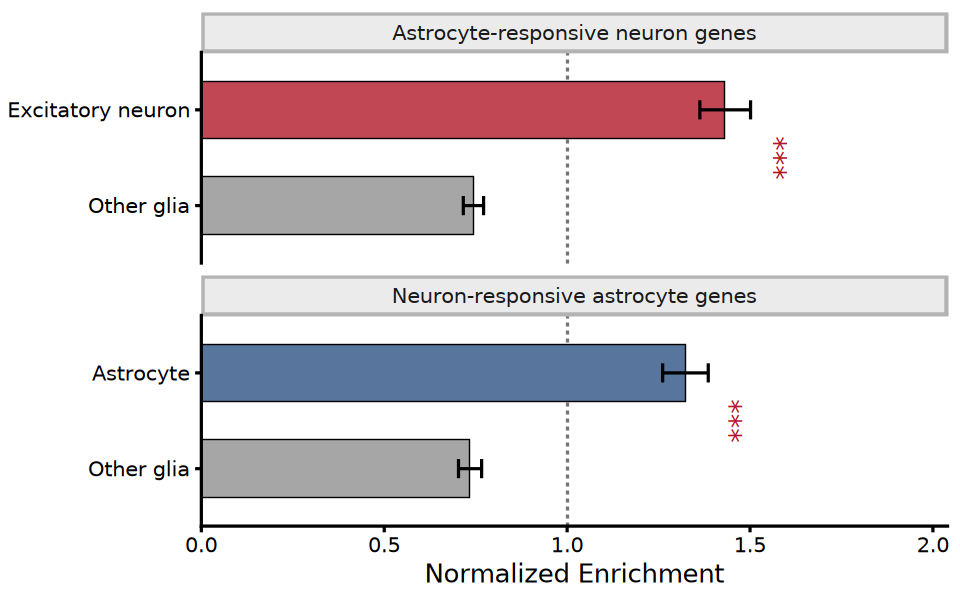

In [2]:
enr <- res$enrichment
enr$trans_group <- factor(enr$trans_group, levels = c("Other glia", "Astrocyte", "Excitatory neuron"))
con <- res$contrast
con$x <- tapply(enr$normalized_ci_high, enr$scenario, max)[con$scenario] * 1.06

cols <- c("Excitatory neuron" = "#C24755", "Astrocyte" = "#58769D", "Other glia" = "grey65")

p <- ggplot(enr, aes(y = trans_group, x = normalized_enrichment, fill = trans_group)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey45") +
  geom_col(width = 0.6, colour = "black", linewidth = 0.3) +
  geom_errorbar(aes(xmin = normalized_ci_low, xmax = normalized_ci_high), orientation = "y", width = 0.2) +
  geom_text(data = con, aes(x = x, y = 1.5, label = label), inherit.aes = FALSE,
            colour = "#B2182B", size = 6, angle = 90) +
  facet_wrap(~ scenario, ncol = 1, scales = "free_y") +
  scale_fill_manual(values = cols, guide = "none") +
  scale_x_continuous(limits = c(0, 2), expand = expansion(mult = c(0, 0.02))) +
  labs(x = "Normalized Enrichment", y = NULL) +
  theme_classic(base_size = 15) +
  theme(strip.background = element_rect(fill = "grey92", colour = "grey70"))

options(repr.plot.width = 8, repr.plot.height = 5)
p